In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

c:\Users\princ\ALL PROGRAMS\DATA-SCIENCE\LANGRAPH\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

True

In [3]:
class SubState(TypedDict):

    input_text: str
    translated_text: str

In [4]:
subgraph_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash-lite')

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [5]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["input_text"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [6]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)
subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

parent Graph

In [7]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str
    

In [8]:
parent_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash-lite')

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [9]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [10]:
def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [11]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

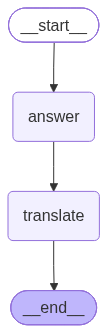

In [12]:
graph = parent_builder.compile()

graph

In [18]:
result = graph.invoke({'question': 'What is quantum physics'})

In [19]:
print(result['answer_hin'])

क्वांटम भौतिकी भौतिकी का एक **मौलिक सिद्धांत है जो परमाणुओं और उप-परमाणु कणों के पैमाने पर प्रकृति के भौतिक गुणों का वर्णन करता है।** यह एक ऐसा क्षेत्र है जहाँ शास्त्रीय भौतिकी के नियम, वह भौतिकी जिसका हम अपने रोजमर्रा के जीवन में अनुभव करते हैं, टूट जाते हैं।

यहाँ बताया गया है कि क्वांटम भौतिकी इतना अनूठा और महत्वपूर्ण क्यों है:

**मुख्य अवधारणाएँ और सिद्धांत:**

*   **क्वांटीकरण (Quantization):** यहीं से "क्वांटम" नाम आया है। इसका मतलब है कि कुछ भौतिक गुण, जैसे ऊर्जा, संवेग और कोणीय संवेग, एक सतत सीमा में नहीं बल्कि अलग-अलग, विशिष्ट पैकेट या "क्वांटा" में मौजूद होते हैं। एक सीढ़ी की कल्पना करें जहाँ आप केवल एक पायदान पर हो सकते हैं, पायदानों के बीच में नहीं।
*   **तरंग-कण द्वैत (Wave-Particle Duality):** शायद सबसे दिमाग घुमा देने वाली अवधारणा। क्वांटम वस्तुएँ, जैसे इलेक्ट्रॉन और फोटॉन (प्रकाश कण), तरंगों और कणों दोनों की विशेषताओं को प्रदर्शित कर सकती हैं। कभी-कभी वे छोटे, स्थानीयकृत गेंदों की तरह व्यवहार करते हैं, और कभी-कभी वे तालाब की लहरों की तरह फैल जाते हैं।
*   **अध्यारोपण (S

In [20]:
print(result['answer_eng'])

Quantum physics is a **fundamental theory in physics that describes the physical properties of nature at the scale of atoms and subatomic particles.** It's a realm where the rules of classical physics, the physics we experience in our everyday lives, break down.

Here's a breakdown of what makes quantum physics so unique and important:

**Key Concepts and Principles:**

*   **Quantization:** This is where the name "quantum" comes from. It means that certain physical properties, like energy, momentum, and angular momentum, don't exist in a continuous range but rather in discrete, specific packets or "quanta." Imagine a staircase where you can only be on a step, not in between steps.
*   **Wave-Particle Duality:** Perhaps the most mind-bending concept. Quantum objects, like electrons and photons (light particles), can exhibit characteristics of both waves and particles. Sometimes they behave like tiny, localized balls, and other times they spread out like ripples on a pond.
*   **Superpo